# Exam Score: A Regression Problem

## Data Preparation

### Load and inspect. Check the shape, data types, missing values and duplicates.

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib

In [64]:
df = pd.read_csv(r"C:\Users\pc\Downloads\Exam_Score_Prediction.csv")

In [65]:
df

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,19997,18,other,bba,6.50,71.3,yes,5.0,good,self-study,low,easy,86.5
19996,19998,18,male,b.com,3.71,41.6,no,5.9,average,coaching,medium,moderate,60.9
19997,19999,19,other,diploma,7.88,68.2,yes,4.6,poor,group study,low,easy,64.5
19998,20000,19,male,bba,4.60,76.3,no,6.1,good,self-study,medium,moderate,79.0


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        20000 non-null  int64  
 1   age               20000 non-null  int64  
 2   gender            20000 non-null  object 
 3   course            20000 non-null  object 
 4   study_hours       20000 non-null  float64
 5   class_attendance  20000 non-null  float64
 6   internet_access   20000 non-null  object 
 7   sleep_hours       20000 non-null  float64
 8   sleep_quality     20000 non-null  object 
 9   study_method      20000 non-null  object 
 10  facility_rating   20000 non-null  object 
 11  exam_difficulty   20000 non-null  object 
 12  exam_score        20000 non-null  float64
dtypes: float64(4), int64(2), object(7)
memory usage: 2.0+ MB


In [67]:
df.head().T

,0,1,2,3,4
student_id,1,2,3,4,5
age,17,23,22,20,20
gender,male,other,male,other,female
course,diploma,bca,b.sc,diploma,diploma
study_hours,2.78,3.37,7.88,0.67,0.89
class_attendance,92.9,64.8,76.8,48.4,71.6
internet_access,yes,yes,yes,yes,yes
sleep_hours,7.4,4.6,8.5,5.8,9.8
sleep_quality,poor,average,poor,average,poor
study_method,coaching,online videos,coaching,online videos,coaching


In [68]:
# Checking some statistical information on Numerical fields. Trying to pinpoint some outliers.
df.describe()

,student_id,age,study_hours,class_attendance,sleep_hours,exam_score
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000
mean,10000.504600,20.473300,4.007604,70.017365,7.00856,62.513225
std,5773.654959,2.284458,2.308313,17.282262,1.73209,18.908491
min,1.000000,17.000000,0.080000,40.600000,4.10000,19.599000
25%,5000.750000,18.000000,2.000000,55.100000,5.50000,48.800000
50%,10000.500000,20.000000,4.040000,69.900000,7.00000,62.600000
75%,15000.250000,22.000000,6.000000,85.000000,8.50000,76.300000
max,20001.000000,24.000000,7.910000,99.400000,9.90000,100.000000


In [69]:
df.dtypes

student_id            int64
age                   int64
gender               object
course               object
study_hours         float64
class_attendance    float64
internet_access      object
sleep_hours         float64
sleep_quality        object
study_method         object
facility_rating      object
exam_difficulty      object
exam_score          float64
dtype: object

In [70]:
# Checking for any missing information.
df.isnull().sum()

student_id          0
age                 0
gender              0
course              0
study_hours         0
class_attendance    0
internet_access     0
sleep_hours         0
sleep_quality       0
study_method        0
facility_rating     0
exam_difficulty     0
exam_score          0
dtype: int64

In [71]:
# checking duplicates
df.duplicated().sum()

np.int64(0)

## EDA

<Axes: xlabel='exam_score', ylabel='Count'>

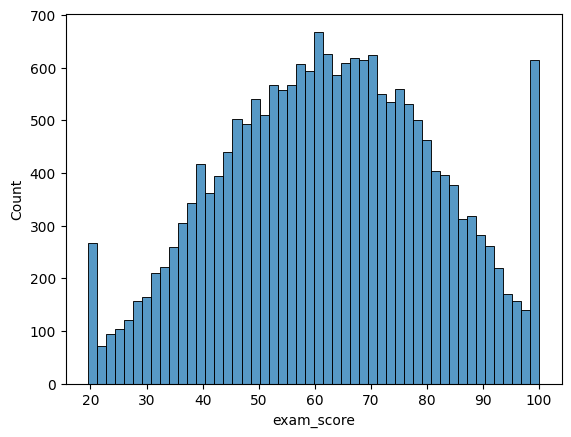

In [72]:
sns.histplot(df.exam_score, bins=50)

In [73]:
def barplotsColumns(autos,nLower = 2,nUpper = 100):
    nColumns = 3
    autos = autos[[col for col in autos if autos.nunique()[col] > nLower and autos.nunique()[col] < nUpper]] 
    _, nCol = autos.shape
    nGraphRow = (nCol + nColumns - 1) / nColumns
    fig = plt.figure(num = None, figsize = (7 * 6, int(4 * nGraphRow)), dpi = 80, facecolor = 'w', edgecolor = 'k')
    for i in range(nCol):
        plt.subplot(int(nGraphRow), nColumns, i + 1)
        columnDf = autos.iloc[:, i]
        if (not np.issubdtype(type(columnDf.iloc[0]), np.number)):
            valueCounts = columnDf.value_counts()
            valueCounts.plot.bar()
        else:
            columnDf.hist()
        plt.ylabel('Counts')
        plt.title('{}'.format(list(autos)[i]))
        
    fig.savefig('high_view.jpg')

    plt.show()

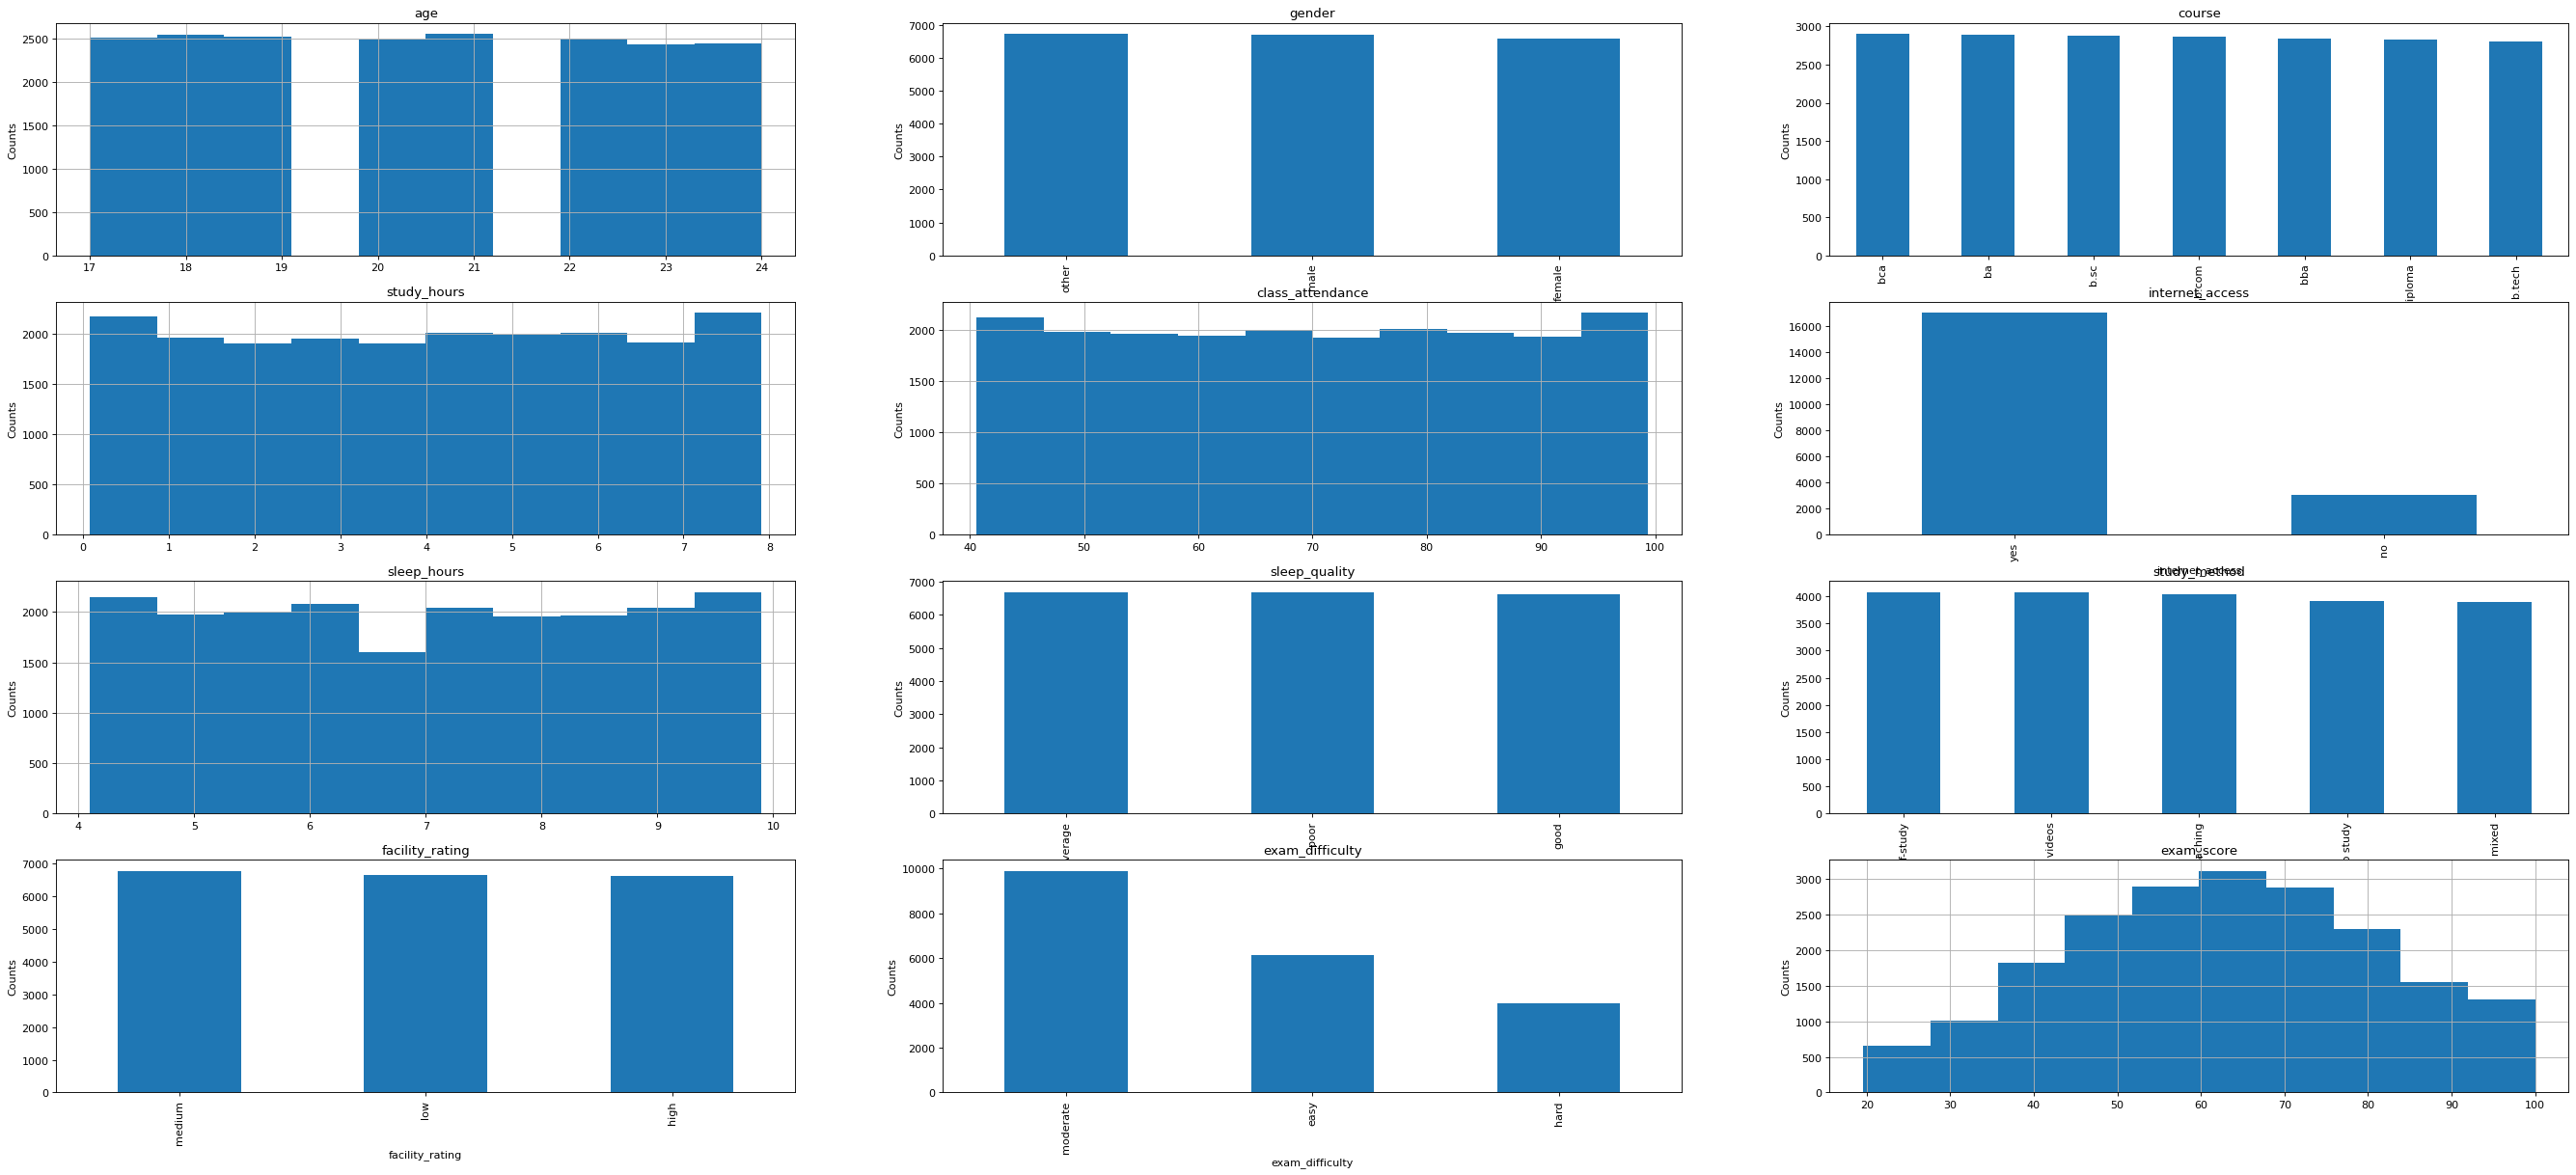

In [74]:
# general view of feature distributions
barplotsColumns(df, nLower = 1, nUpper = 1000)

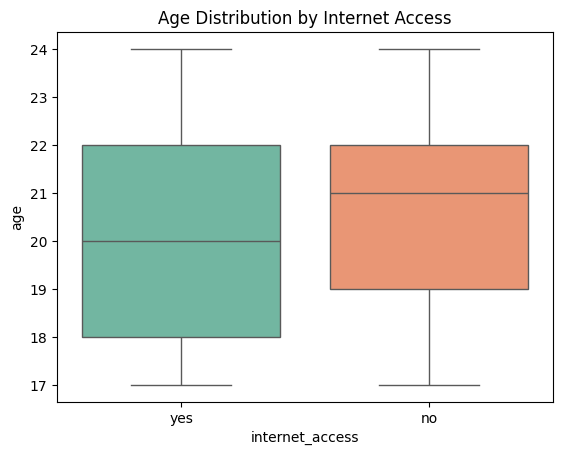

In [75]:
plt.figure()
sns.boxplot(data=df, x='internet_access', y='age', palette='Set2')
plt.title('Age Distribution by Internet Access')
plt.show()

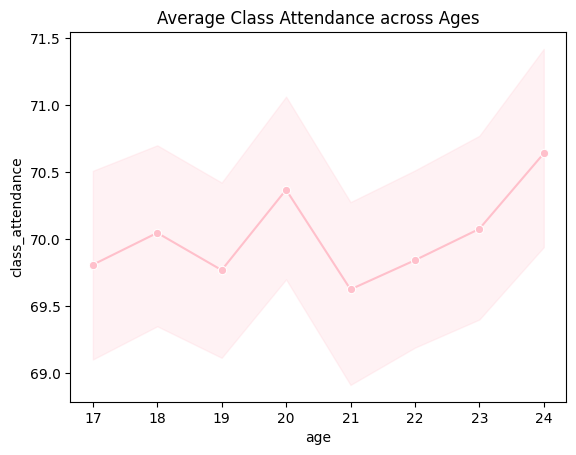

In [76]:
plt.figure()
sns.lineplot(data=df, x='age', y='class_attendance', marker='o', color='pink')
plt.title('Average Class Attendance across Ages')
plt.show()

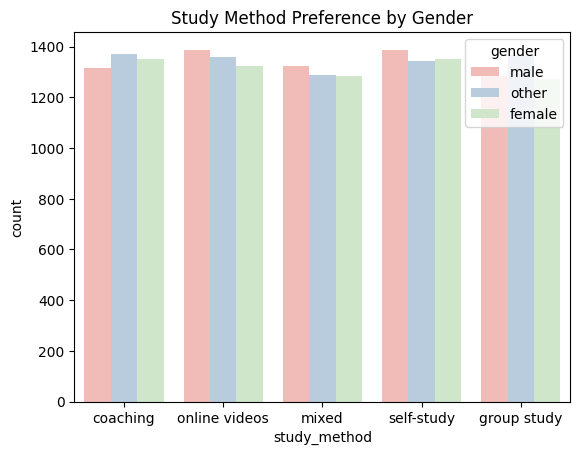

In [77]:
plt.figure()
sns.countplot(data=df, x='study_method', hue='gender', palette='Pastel1')
plt.title('Study Method Preference by Gender')
plt.show()

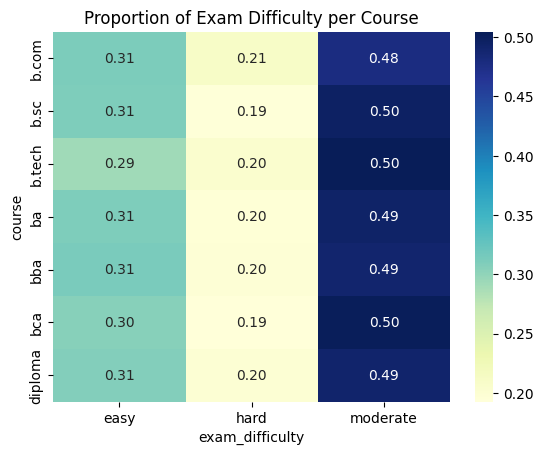

In [78]:
plt.figure()
course_diff = pd.crosstab(df['course'], df['exam_difficulty'], normalize='index')
sns.heatmap(course_diff, annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Proportion of Exam Difficulty per Course')
plt.show()

count    20000.000000
mean        62.513225
std         18.908491
min         19.599000
25%         48.800000
50%         62.600000
75%         76.300000
max        100.000000
Name: exam_score, dtype: float64
Skew: -0.04905862218606845


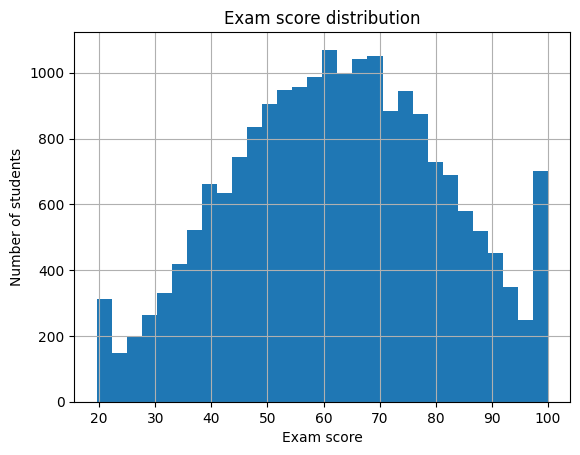

study_hours         0.717788
class_attendance    0.308850
sleep_hours         0.133222
age                 0.006522
Name: exam_score, dtype: float64


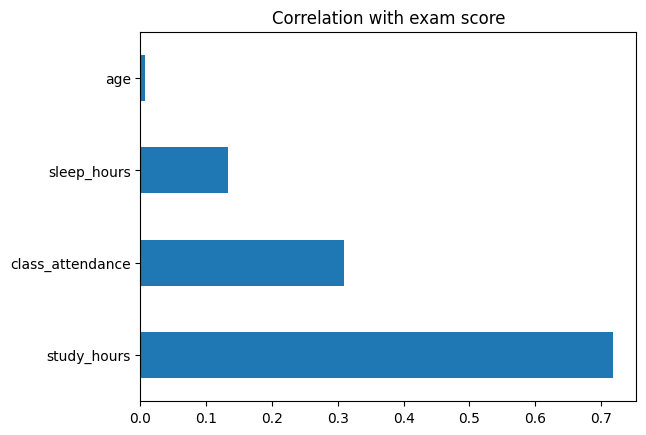

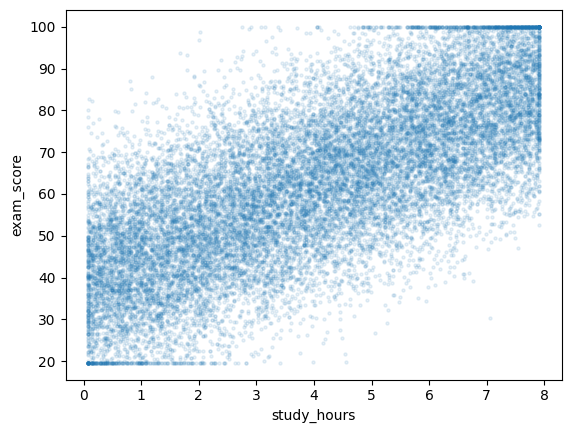

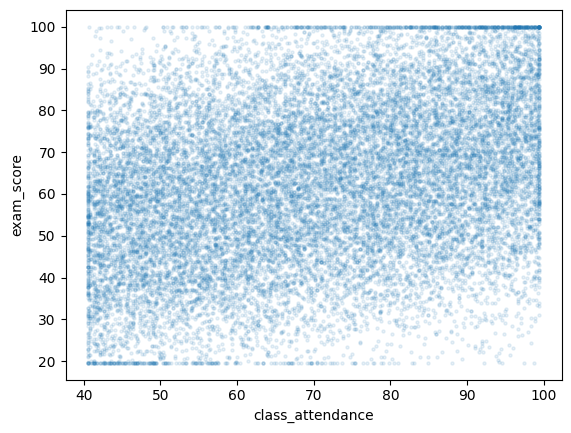

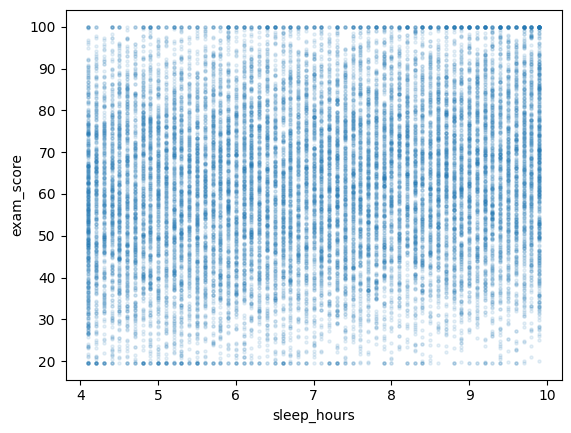

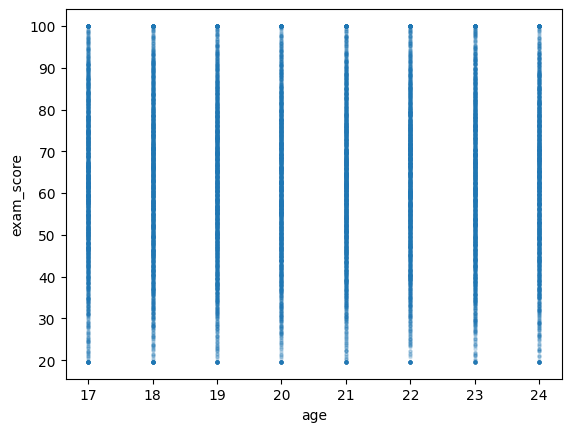

In [79]:
# 1. Score distribution
print(df["exam_score"].describe())
print("Skew:", df["exam_score"].skew())

df["exam_score"].hist(bins=30)
plt.xlabel("Exam score"); plt.ylabel("Number of students")
plt.title("Exam score distribution")
plt.show()

# 2. Correlation of each numeric feature with the score
num = df.select_dtypes("number").drop(columns="student_id")   # drop the ID
corr = num.corr()["exam_score"].drop("exam_score").sort_values(ascending=False)
print(corr)

corr.plot.barh(title="Correlation with exam score")
plt.show()

# 3. Scatter plots to check the shape of each relationship
for col in corr.index:
    plt.scatter(df[col], df["exam_score"], alpha=0.1, s=5)
    plt.xlabel(col); plt.ylabel("exam_score"); plt.show()

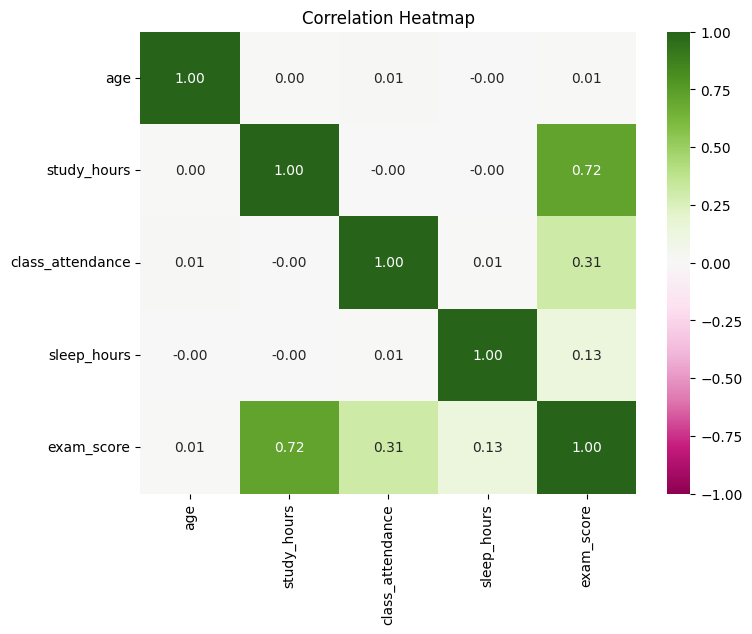

In [18]:
num = df.select_dtypes("number").drop(columns="student_id")   # numeric only, no ID
correlation_matrix = num.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="PiYG", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

## Model Evaluation

In [19]:
df_full, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full, test_size=0.25, random_state=42)

In [20]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [21]:
y_train = df_train['exam_score']
y_val = df_val['exam_score']
y_test = df_test['exam_score']

In [22]:
del df_train['exam_score']
del df_val['exam_score']
del df_test['exam_score']

In [23]:
df_train.head()

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty
0,16114,21,male,b.sc,5.70,60.5,yes,7.2,good,group study,low,moderate
1,18794,21,female,diploma,7.77,52.2,yes,4.6,good,coaching,medium,easy
2,16339,18,male,ba,3.98,48.7,yes,6.9,poor,self-study,high,moderate
3,15055,22,other,ba,6.51,87.0,no,4.6,average,mixed,medium,easy
4,7540,22,female,diploma,2.60,66.0,yes,4.6,average,self-study,low,moderate


### Features importance analysis

In [24]:
from sklearn.metrics import mutual_info_score

In [26]:
import pandas as pd
from sklearn.metrics import mutual_info_score

# target as a Series aligned with df_train's rows
y = pd.Series(y_train, index=df_train.index)

# the target is continuous, so bin it before using mutual information
y_binned = pd.qcut(y, q=5, duplicates='drop')

categorical = df_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

def calculate_mi(series):
    return mutual_info_score(series, y_binned)

df_mi = df_train[categorical].apply(calculate_mi)
df_mi = df_mi.sort_values(ascending=False).to_frame(name='MI')
display(df_mi)

,MI
sleep_quality,0.017868
study_method,0.016298
facility_rating,0.010836
course,0.000888
gender,0.000570
exam_difficulty,0.000353
internet_access,0.000288


In [31]:
numerical = ['age', 'study_hours', 'class_attendance', 'sleep_hours']
target = pd.Series(y_train, index=df_train.index)   # y_train must match df_train's rows

a = df_train[numerical].corrwith(target).to_frame('correlation')
a['abs_corr'] = a['correlation'].abs()
a.sort_values('abs_corr', ascending=False)

,correlation,abs_corr
study_hours,0.716945,0.716945
class_attendance,0.309128,0.309128
sleep_hours,0.126649,0.126649
age,0.003812,0.003812


#this shows that study hours IS important!

In [32]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier  
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text
import matplotlib.pyplot as plt
import xgboost as xgb


In [33]:
from sklearn.feature_extraction import DictVectorizer

# 1. drop the ID: it's unique per row, so it's useless as a feature
for d in (df_train, df_val, df_test):
    d.drop(columns=['student_id'], inplace=True, errors='ignore')

# 2. rows -> dictionaries
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

# 3. dictionaries -> numeric matrix
dv = DictVectorizer(sparse=False)          # dense avoids the int64 sparse error
X_train = dv.fit_transform(train_dicts)    # learn the columns from TRAIN only
X_val = dv.transform(val_dicts)            # reuse them for validation
X_test = dv.transform(test_dicts)          # and for test

print(X_train.shape, X_val.shape, X_test.shape)
print(dv.get_feature_names_out()[:10])

(12000, 30) (4000, 30) (4000, 30)
['age' 'class_attendance' 'course=b.com' 'course=b.sc' 'course=b.tech'
 'course=ba' 'course=bba' 'course=bca' 'course=diploma'
 'exam_difficulty=easy']


In [80]:
from sklearn.feature_extraction import DictVectorizer

# Convert DataFrames into dictionaries
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

# Convert dictionaries into numerical matrices
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

print(X_train.shape, X_val.shape, X_test.shape)

(12000, 30) (4000, 30) (4000, 30)


numerical  : ['age', 'study_hours', 'class_attendance', 'sleep_hours']
categorical: ['gender', 'course', 'internet_access', 'sleep_quality', 'study_method', 'facility_rating', 'exam_difficulty']


,correlation,abs_corr
study_hours,0.716945,0.716945
class_attendance,0.309128,0.309128
sleep_hours,0.126649,0.126649
age,0.003812,0.003812


,MI
sleep_quality,0.017868
study_method,0.016298
facility_rating,0.010836
course,0.000888
gender,0.000570
exam_difficulty,0.000353
internet_access,0.000288


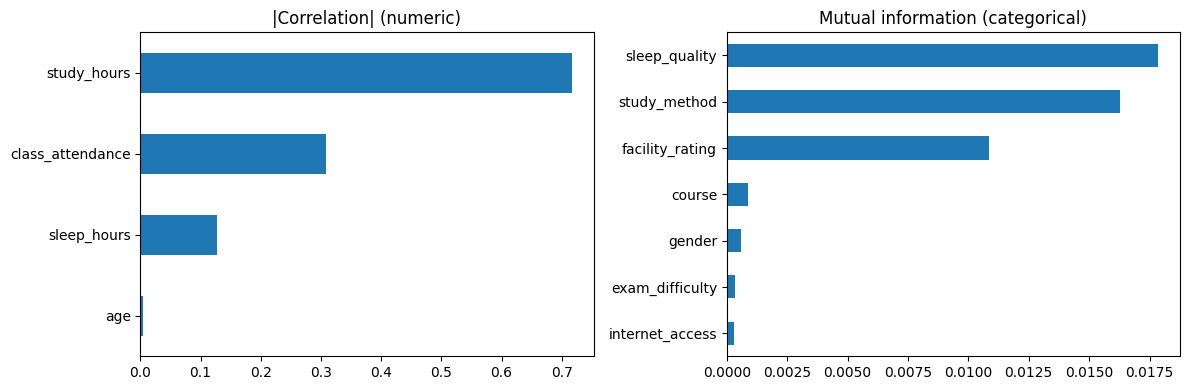

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mutual_info_score

# target as a Series aligned with df_train's rows
y = pd.Series(y_train, index=df_train.index)

numerical = df_train.select_dtypes(include='number').columns.tolist()
categorical = df_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
print('numerical  :', numerical)
print('categorical:', categorical)

# 1. numeric features: correlation with the target (strongest first)
corr = df_train[numerical].corrwith(y).to_frame('correlation')
corr['abs_corr'] = corr['correlation'].abs()
corr = corr.sort_values('abs_corr', ascending=False)
display(corr)

# 2. categorical features: mutual information with a binned target
y_binned = pd.qcut(y, q=5, duplicates='drop')

def calculate_mi(series):
    return mutual_info_score(series, y_binned)

df_mi = df_train[categorical].apply(calculate_mi)
df_mi = df_mi.sort_values(ascending=False).to_frame(name='MI')
display(df_mi)

# 3. quick visual comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
corr['abs_corr'].sort_values().plot.barh(ax=axes[0], title='|Correlation| (numeric)')
df_mi['MI'].sort_values().plot.barh(ax=axes[1], title='Mutual information (categorical)')
plt.tight_layout()
plt.show()

In [81]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(model, model_name, X_train, y_train, X_val, y_val):

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_val)

    # Calculate metrics
    mae = mean_absolute_error(y_val, y_pred)
    mse = mean_squared_error(y_val, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_val, y_pred)

    return {
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

In [84]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():

    result = evaluate_model(
        model,
        name,
        X_train,
        y_train,
        X_val,
        y_val
    )

    results.append(result)

# Display comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by='RMSE')

print(results_df)

               Model        MAE         MSE       RMSE  R2 Score
0  Linear Regression   7.822379   94.506184   9.721429  0.735038
1              Ridge   7.822453   94.507454   9.721494  0.735034
5  Gradient Boosting   7.918551   96.394801   9.818085  0.729743
4      Random Forest   8.249431  104.570577  10.225976  0.706821
2              Lasso   8.742409  117.674978  10.847810  0.670081
3      Decision Tree  11.740841  216.263259  14.705892  0.393674


In [83]:
from xgboost import XGBRegressor

models['XGBoost'] = XGBRegressor(
    random_state=42,
    n_estimators=100
)

###  Hyperparameter Tuning

In [85]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.model_selection import GridSearchCV

models = {
    'Linear Regression': {
        'model': LinearRegression(),
        'params': {}
    },

    'Ridge': {
        'model': Ridge(),
        'params': {
            'alpha': [0.01, 0.1, 1, 10, 100]
        }
    },

    'Lasso': {
        'model': Lasso(max_iter=10000),
        'params': {
            'alpha': [0.001, 0.01, 0.1, 1, 10]
        }
    },

    'Decision Tree': {
        'model': DecisionTreeRegressor(random_state=42),
        'params': {
            'max_depth': [None, 5, 10, 15, 20],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
    },

    'Random Forest': {
        'model': RandomForestRegressor(random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [None, 10, 20],
            'min_samples_split': [2, 5],
            'min_samples_leaf': [1, 2]
        }
    },

    'Gradient Boosting': {
        'model': GradientBoostingRegressor(random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'learning_rate': [0.01, 0.05, 0.1],
            'max_depth': [2, 3, 5]
        }
    }
}

In [86]:
best_model = RandomForestRegressor(random_state=42)

best_model.fit(X_train, y_train)

y_test_pred = best_model.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Test RMSE:", np.sqrt(
    mean_squared_error(y_test, y_test_pred)
))

print("Test R2:", r2_score(y_test, y_test_pred))

Test MAE: 8.3250959375
Test RMSE: 10.318696469721006
Test R2: 0.7023304877326375


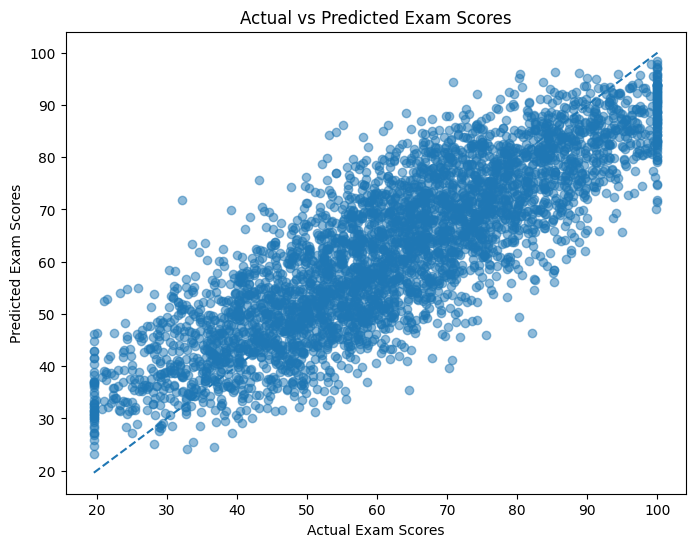

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Actual vs Predicted Exam Scores")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()